# Heart Disease Prediction System
## 1. Live Deployment URL
**Previous version (Cleveland / UCI model):** https://heart-disease-prediction-gg.streamlit.app/

> This is the URL recorded before the upgrade. The app code and model in this project have since been changed to the Kaggle-trained model, so the live app must be **redeployed**. Until the new deployment has been verified, treat the URL above as the previous version. Its current status has not been verified from this notebook.

## 2. Assignment Objective
Develop an end-to-end Machine Learning System that predicts the presence of heart disease, following a simplified ML workflow: select **exactly four** input attributes, train a classification model, evaluate it on held-out data, save it, and prepare it for cloud deployment.

This version upgrades the original UCI Cleveland experiment (297 usable rows) to the larger Kaggle *Heart Failure Prediction* dataset (918 rows). The Cleveland experiment is kept as **Experiment A (baseline)**; the Kaggle experiment is **Experiment B**.

## 3. Dataset Sources
| | Experiment A (baseline) | Experiment B (final model) |
|---|---|---|
| Source | UCI Machine Learning Repository, *Heart Disease* — Cleveland subset (`processed.cleveland.data`) | Kaggle, *Heart Failure Prediction Dataset* by fedesoriano — `heart.csv` |
| URL | https://archive.ics.uci.edu/dataset/45/heart+disease | https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction |
| License | CC BY 4.0 (UCI) | Open Database License (ODbL 1.0), as listed by Kaggle |
| Target | `num` (0–4), binarised: 0 → no disease, 1–4 → disease | `HeartDisease`: 0 = normal, 1 = heart disease |

**Attribution (Kaggle):** fedesoriano. (September 2021). *Heart Failure Prediction Dataset.* Retrieved from https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction. The dataset combines five heart-disease datasets (Cleveland, Hungarian, Switzerland, Long Beach VA, Stalog), so it **already contains Cleveland-derived patients**; the two experiments are therefore not independent populations and the datasets must not be concatenated.

## 4. Import Libraries

In [1]:
import warnings
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report

import heart_pipeline as hp   # shared preprocessing/model code (also used by train_model.py)

warnings.filterwarnings("ignore")
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.0.6


## 5. Load the Original Cleveland Dataset
The original file is kept untouched. Its integer-coded features (`sex`: 1/0, `cp`: 1–4) are used as-is for the baseline.

In [2]:
cleveland = pd.read_csv(hp.CLEVELAND_PATH, header=None, names=hp.CLEVELAND_COLUMNS, na_values="?")
print("Cleveland shape:", cleveland.shape, "| rows with missing values:", int(cleveland.isna().any(axis=1).sum()))
display(cleveland.head())

Cleveland shape: (303, 14) | rows with missing values: 6


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 6. Load the Kaggle Dataset
The raw CSV is loaded once and never modified; cleaning happens on a separate working copy.

In [3]:
raw = hp.load_kaggle()
display(raw.head())
print("Shape:", raw.shape)
print("Columns:", list(raw.columns))

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


Shape: (918, 12)
Columns: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']


## 7. Inspect and Understand the Kaggle Data

In [4]:
print(raw.dtypes, "\n")
print("Missing values per column:\n", raw.isna().sum(), "\n")
print("Fully duplicated rows:", raw.duplicated().sum())
print("Duplicated rows on the four chosen predictors only:", raw[hp.FEATURES].duplicated().sum())
print("\nTarget distribution (HeartDisease):")
print(raw[hp.KAGGLE_TARGET].value_counts().sort_index())
print("\nSex:", raw["Sex"].value_counts().to_dict())
print("ChestPainType:", raw["ChestPainType"].value_counts().to_dict())
display(raw[["Age", "MaxHR"]].describe())
print("Zero-valued Cholesterol rows (column NOT used by the model):", (raw["Cholesterol"] == 0).sum())
print("Zero-valued RestingBP rows (column NOT used by the model):", (raw["RestingBP"] == 0).sum())

Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object 

Missing values per column:
 Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64 

Fully duplicated rows: 0
Duplicated rows on the four chosen predictors only: 59

Target distribution (HeartDisease):
HeartDisease
0    410
1    508
Name: count, dtype: int64

Sex: {'M': 725, 'F': 193}
ChestPainType: {'ASY': 496, 'NAP': 203, 'ATA': 173, 'TA': 46}


,Age,MaxHR
count,918.000000,918.000000
mean,53.510893,136.809368
std,9.432617,25.460334
min,28.000000,60.000000
25%,47.000000,120.000000
50%,54.000000,138.000000
75%,60.000000,156.000000
max,77.000000,202.000000


Zero-valued Cholesterol rows (column NOT used by the model): 172
Zero-valued RestingBP rows (column NOT used by the model): 1


## 8. Data Cleaning
Findings and decisions:
* **Missing values:** none in the Kaggle file. Nothing was imputed, and nothing was silently set to 0.
* **Duplicates:** there are no fully duplicated records, so nothing is removed. Many patients share identical values on the four predictors (age, sex, chest-pain type, max HR take few distinct values), which is expected and legitimate — deleting them would remove real patients.
* **Suspicious values:** `Cholesterol == 0` (172 rows) and `RestingBP == 0` (1 row) are physiologically impossible and are really missing data. These columns are **not** used by the four-feature model, so those rows are kept. (They would need handling if those columns were ever added.)
* **Chosen features:** `Age` (28–77) and `MaxHR` (60–202) lie in plausible ranges; `Sex` ∈ {M, F}; `ChestPainType` ∈ {TA, ATA, NAP, ASY}.

`hp.clean_kaggle` works on a copy, keeps only rows with valid values in the four predictors and the target, and reports how many rows (if any) were dropped.

In [5]:
work = hp.clean_kaggle(raw)
print(f"Rows before: {len(raw)} | after: {len(work)} | dropped: {len(raw) - len(work)}")

Rows before: 918 | after: 918 | dropped: 0


## 9. Exploratory Data Analysis

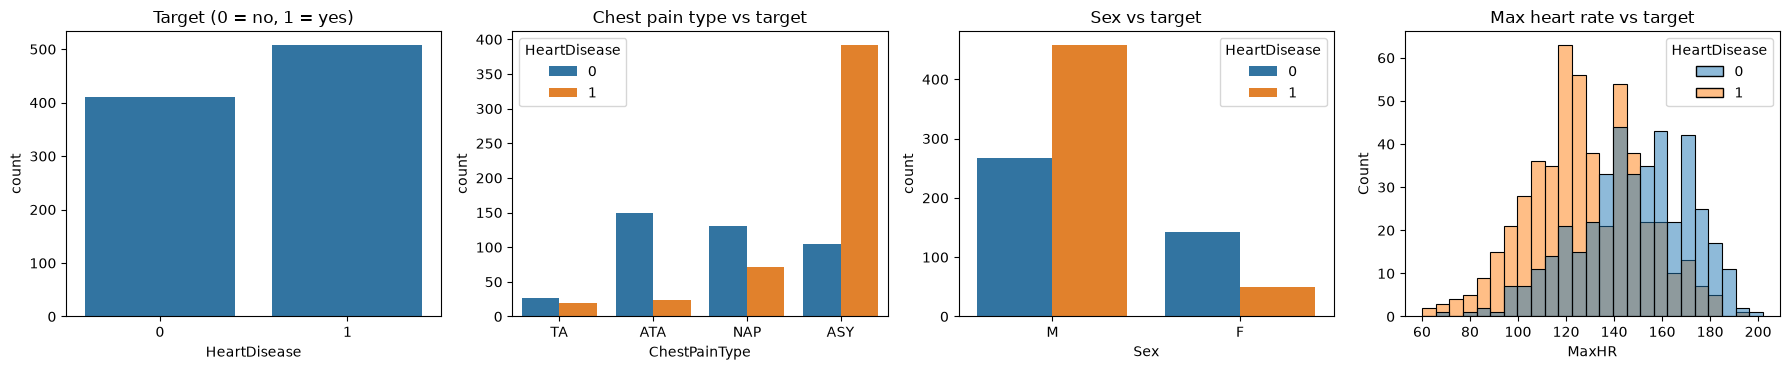

,Age,MaxHR
HeartDisease,,
0,50.6,148.2
1,55.9,127.7


In [6]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
sns.countplot(x=hp.KAGGLE_TARGET, data=work, ax=ax[0]); ax[0].set_title("Target (0 = no, 1 = yes)")
sns.countplot(x="ChestPainType", hue=hp.KAGGLE_TARGET, data=work, order=hp.CHEST_PAIN_CATEGORIES, ax=ax[1]); ax[1].set_title("Chest pain type vs target")
sns.countplot(x="Sex", hue=hp.KAGGLE_TARGET, data=work, ax=ax[2]); ax[2].set_title("Sex vs target")
sns.histplot(data=work, x="MaxHR", hue=hp.KAGGLE_TARGET, bins=25, ax=ax[3]); ax[3].set_title("Max heart rate vs target")
plt.tight_layout(); plt.show()
display(work.groupby(hp.KAGGLE_TARGET)[["Age", "MaxHR"]].mean().round(1))

## 10. Select Exactly Four Input Attributes
| Kaggle column | Meaning | Cleveland equivalent | Type |
|---|---|---|---|
| `Age` | age in years | `age` | numeric |
| `Sex` | `M` / `F` | `sex` (1/0) | categorical (nominal) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | `cp` (1–4) | categorical (nominal) |
| `MaxHR` | maximum heart rate achieved | `thalach` | numeric |

The encodings are **not** interchangeable with Cleveland (strings vs. integer codes), so they are handled separately.

In [7]:
X = work[hp.FEATURES]
print("Selected features:", list(X.columns))
assert X.shape[1] == 4 and hp.KAGGLE_TARGET not in X.columns

Selected features: ['Age', 'Sex', 'ChestPainType', 'MaxHR']


## 11. Define the Target
Kaggle `HeartDisease`: **0 = no heart disease, 1 = heart disease present**. It is used directly and never enters the feature matrix.

This differs from Cleveland's original `num` column (0–4 severity), which the baseline binarises as `num > 0`.

In [8]:
y = work[hp.KAGGLE_TARGET]
print(y.value_counts().sort_index())

HeartDisease
0    410
1    508
Name: count, dtype: int64


## 12. Encode Categorical Features
A scikit-learn `ColumnTransformer` inside a `Pipeline`:
* `Age`, `MaxHR` → `StandardScaler` (important for an RBF-kernel SVC; fitted on training data only)
* `Sex`, `ChestPainType` → `OneHotEncoder` (nominal categories, so no false ordering; `handle_unknown="ignore"` so unseen categories do not crash prediction)

Because the transformer lives in the pipeline, it is fitted only when `fit` is called on the training split.

In [9]:
pipeline = hp.build_pipeline()
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the o

## 13. Split the Data
80 / 20 split, stratified on the target, `random_state=0` (same protocol as the baseline).

In [10]:
X_train, X_test, y_train, y_test = hp.split_kaggle(work)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train class balance:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test class balance: ", y_test.value_counts(normalize=True).round(3).to_dict())

Train: (734, 4) Test: (184, 4)
Train class balance: {1: 0.553, 0: 0.447}
Test class balance:  {1: 0.554, 0: 0.446}


## 14. Train the Model
Same classifier as the original project: `SVC(gamma='auto', random_state=0)`, now preceded by the preprocessing step.

In [11]:
model = hp.build_pipeline().fit(X_train, y_train)
print(model)
print("Encoder categories learned from training data:", model.named_steps["preprocess"].named_transformers_["cat"].categories_)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'MaxHR']),
                                                 ('cat',
                                                  OneHotEncoder(categories=[['M',
                                                                             'F'],
                                                                            ['TA',
                                                                             'ATA',
                                                                             'NAP',
                                                                             'ASY']],
                                                                handle_unknown='ignore'),
                                                  ['Sex', 'ChestPainType'])])),
                ('model', SVC(gamma='auto', random_state=0))])
Encoder categories learned from t

## 15. Evaluate the Model
All metrics below come from the 20 % held-out test set. ROC-AUC is computed from the SVC **decision scores** (a ranking measure); these are *not* calibrated probabilities, and the app does not display probabilities.

  accuracy: 0.7880
 precision: 0.7944
    recall: 0.8333
        f1: 0.8134
   roc_auc: 0.8590



                precision    recall  f1-score   support

No disease (0)       0.78      0.73      0.75        82
   Disease (1)       0.79      0.83      0.81       102

      accuracy                           0.79       184
     macro avg       0.79      0.78      0.78       184
  weighted avg       0.79      0.79      0.79       184



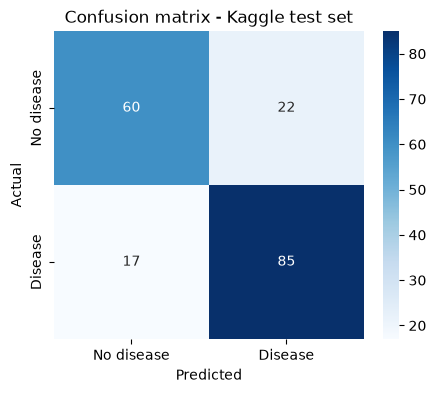

In [12]:
metrics = hp.evaluate(model, X_test, y_test)
for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(f"{k:>10}: {metrics[k]:.4f}")
pred = model.predict(X_test)
print()
print(classification_report(y_test, pred, target_names=["No disease (0)", "Disease (1)"]))
plt.figure(figsize=(5, 4))
sns.heatmap(metrics["confusion_matrix"], annot=True, fmt="d", cmap="Blues",
            xticklabels=["No disease", "Disease"], yticklabels=["No disease", "Disease"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix - Kaggle test set"); plt.show()

### Optional: comparison with other classifiers
Same four predictors, same preprocessing and split. Candidates are compared by **5-fold cross-validation on the training set only**; the test set is shown for information, not used for selection. SVC stays the default unless another model is clearly better under this protocol.

In [13]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
candidates = {
    "SVC (default)": hp.build_pipeline(),
    "Logistic Regression": hp.build_pipeline(LogisticRegression(max_iter=1000)),
    "Random Forest": hp.build_pipeline(RandomForestClassifier(n_estimators=200, random_state=0)),
}
rows = []
for name, est in candidates.items():
    cv_acc = cross_val_score(est, X_train, y_train, cv=cv, scoring="accuracy")
    m = hp.evaluate(est.fit(X_train, y_train), X_test, y_test)
    rows.append({"model": name, "cv_accuracy_mean": cv_acc.mean(), "cv_accuracy_std": cv_acc.std(),
                 "test_accuracy": m["accuracy"], "test_f1": m["f1"], "test_roc_auc": m["roc_auc"]})
display(pd.DataFrame(rows).round(4))

,model,cv_accuracy_mean,cv_accuracy_std,test_accuracy,test_f1,test_roc_auc
0,SVC (default),0.7752,0.0361,0.7880,0.8134,0.8590
1,Logistic Regression,0.7848,0.0403,0.7663,0.7943,0.8558
2,Random Forest,0.7535,0.0266,0.6957,0.7358,0.7496


## 16. Compare the Baseline and Kaggle Experiments

In [14]:
base = hp.run_cleveland_baseline()      # Experiment A: original workflow, reproduced
print("Experiment A confusion matrix:", base["confusion_matrix"])
cmp = pd.DataFrame({
    "Experiment A: Cleveland": {"rows used": base["n_rows"], "train / test": f"{base['n_train']} / {base['n_test']}",
        "features": "age, sex(0/1), cp(1-4), thalach (raw integers)", "target": "num > 0",
        "accuracy": base["accuracy"], "precision": base["precision"], "recall": base["recall"],
        "f1": base["f1"], "roc_auc": base["roc_auc"]},
    "Experiment B: Kaggle": {"rows used": len(work), "train / test": f"{len(X_train)} / {len(X_test)}",
        "features": "Age, Sex, ChestPainType (one-hot), MaxHR; scaled", "target": "HeartDisease",
        "accuracy": metrics["accuracy"], "precision": metrics["precision"], "recall": metrics["recall"],
        "f1": metrics["f1"], "roc_auc": metrics["roc_auc"]},
})
display(cmp)

Experiment A confusion matrix: [[25, 7], [17, 11]]


,Experiment A: Cleveland,Experiment B: Kaggle
rows used,297,918
train / test,237 / 60,734 / 184
features,"age, sex(0/1), cp(1-4), thalach (raw integers)","Age, Sex, ChestPainType (one-hot), MaxHR; scaled"
target,num > 0,HeartDisease
accuracy,0.6,0.788043
precision,0.611111,0.794393
recall,0.392857,0.833333
f1,0.478261,0.813397
roc_auc,0.603795,0.859039


**Reading the comparison carefully.** Experiment A reproduces the original notebook's configuration and its reported 60.00 % test accuracy exactly. Experiment B differs in several ways at once: more rows (918 vs 297), a different test set (184 vs 60 patients — small test sets give noisy metrics), string categories with one-hot encoding, feature scaling, and a different target definition. The Kaggle data also pools several source populations and collection procedures (including Cleveland patients). The score difference therefore **cannot be attributed to dataset size alone**.

## 17. Save the Model
The whole fitted pipeline (preprocessing + SVC) is saved together with metadata, so the app needs no other runtime file. The previous Cleveland model is preserved as `baseline_cleveland_model.pkl`.

In [15]:
artifact = {
    "pipeline": model,
    "features": hp.FEATURES,
    "target": hp.KAGGLE_TARGET,
    "target_definition": {0: "No heart disease", 1: "Heart disease present"},
    "categories": {"Sex": hp.SEX_CATEGORIES, "ChestPainType": hp.CHEST_PAIN_CATEGORIES},
    "dataset": "fedesoriano/heart-failure-prediction (heart.csv)",
    "sklearn_version": sklearn.__version__,
    "test_metrics": metrics,
}
joblib.dump(artifact, hp.MODEL_PATH)
print("Saved:", hp.MODEL_PATH.name)

Saved: heart_disease_model.pkl


## 18. Reload and Test the Saved Model

In [16]:
loaded = joblib.load(hp.MODEL_PATH)
reloaded_metrics = hp.evaluate(loaded["pipeline"], X_test, y_test)
assert reloaded_metrics == metrics, "reloaded model differs"
print("Reloaded model reproduces held-out metrics: OK")

samples = pd.DataFrame([
    {"Age": 63, "Sex": "M", "ChestPainType": "ASY", "MaxHR": 110},
    {"Age": 35, "Sex": "F", "ChestPainType": "ATA", "MaxHR": 175},
    {"Age": 54, "Sex": "M", "ChestPainType": "NAP", "MaxHR": 140},
])[loaded["features"]]
samples["prediction"] = loaded["pipeline"].predict(samples)
samples["meaning"] = samples["prediction"].map(loaded["target_definition"])
display(samples)

Reloaded model reproduces held-out metrics: OK


,Age,Sex,ChestPainType,MaxHR,prediction,meaning
0,63,M,ASY,110,1,Heart disease present
1,35,F,ATA,175,0,No heart disease
2,54,M,NAP,140,0,No heart disease


## 19. Conclusion and Limitations
An SVC pipeline using exactly four predictors (`Age`, `Sex`, `ChestPainType`, `MaxHR`) was trained on the 918-record Kaggle dataset and evaluated on a held-out 20 % test set (metrics above). The Cleveland baseline was reproduced and kept for comparison.

Limitations:
* Only four predictors are used (assignment constraint); clinically important variables are ignored.
* The test set is a single 184-patient split; metrics carry sampling uncertainty.
* The Kaggle data pools several hospitals' datasets and is male-dominated (725 M vs 193 F); the model may not generalise to other populations.
* The two experiments are not a controlled comparison (see Section 16), and the Kaggle data contains Cleveland-derived records.
* **Educational use only.** This is not a clinically validated or diagnostic tool.
* The Streamlit app has been updated locally and tested; it must be redeployed before the live URL reflects this model.